# 01 — Exploratory Data Analysis

---

## Context and Research Question

The yield curve represents bond yields across different maturities. Its evolution reflects market expectations regarding monetary policy, inflation, and economic conditions.

> *This project focuses on **forecasting the US Treasury yield curve using Machine Learning**. The objective is to compare forecasting performance across short-, medium-, and long-term maturities to determine whether some maturities are more predictable than others.*

## Data Source

The analysis is based on historical US Treasury yields obtained from the Federal Reserve Economic Data (FRED) database.

| **Characteristic** | **Description** |
|---|---|
| Source | FRED (Federal Reserve Bank of St. Louis) |
| Market | US Treasury Securities |
| Period | January 2005 – November 2026 |
| Frequency | Daily |
| Unit | Percent (%) |
| Maturities | 3M, 6M, 1Y, 2Y, 3Y, 5Y, 7Y, 10Y, 20Y, 30Y |
| Main comparison | 3M vs 10Y vs 30Y |

## 1. Dataset

The dataset covers **ten maturities ranging from 3 months to 30 years**, with yields expressed in **percent (%)** at a **daily frequency**.

All statistics presented below are calculated directly from the raw CSV files stored in the `data/` directory.

In [38]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate data folder automatically
root = Path.cwd()
data = (root if (root / "data").is_dir() else root.parent) / "data"

# Load and align FRED series
series = dict(zip(
    ["3M", "6M", "1Y", "2Y", "3Y", "5Y", "7Y", "10Y", "20Y", "30Y"],
    ["DGS3MO", "DGS6MO", "DGS1", "DGS2", "DGS3", "DGS5", "DGS7", "DGS10", "DGS20", "DGS30"]
))

df = pd.DataFrame({
    maturity: pd.to_numeric(pd.read_csv(data / f"{code}.csv", index_col=0, parse_dates=True).iloc[:, 0], errors="coerce")
    for maturity, code in series.items()
}).sort_index()

df.index.name = "Date"

print(f"Study period: {df.index.min():%d/%m/%Y} to {df.index.max():%d/%m/%Y}")
print(f"Observations: {len(df):,} | Maturities: {df.shape[1]}")
print("Series:", ", ".join(df.columns))
display(df.head())

Study period: 03/01/2005 to 05/11/2026
Observations: 5,699 | Maturities: 10
Series: 3M, 6M, 1Y, 2Y, 3Y, 5Y, 7Y, 10Y, 20Y, 30Y


,3M,6M,1Y,2Y,3Y,5Y,7Y,10Y,20Y,30Y
Date,,,,,,,,,,
2005-01-03,2.32,2.63,2.79,3.10,3.28,3.64,3.94,4.23,4.84,4.85
2005-01-04,2.33,2.63,2.82,3.20,3.38,3.72,4.02,4.29,4.91,4.91
2005-01-05,2.33,2.63,2.83,3.22,3.39,3.73,4.02,4.29,4.88,4.88
2005-01-06,2.31,2.63,2.82,3.18,3.36,3.71,4.01,4.29,4.88,4.89
2005-01-07,2.32,2.63,2.82,3.20,3.40,3.73,4.03,4.29,4.88,4.88


## 2. Missing Values

,Available observations,Missing values,Missing rate (%)
3M,5466,233,4.09
6M,5466,233,4.09
1Y,5466,233,4.09
2Y,5466,233,4.09
3Y,5466,233,4.09
5Y,5466,233,4.09
7Y,5466,233,4.09
10Y,5466,233,4.09
20Y,5466,233,4.09
30Y,5466,233,4.09


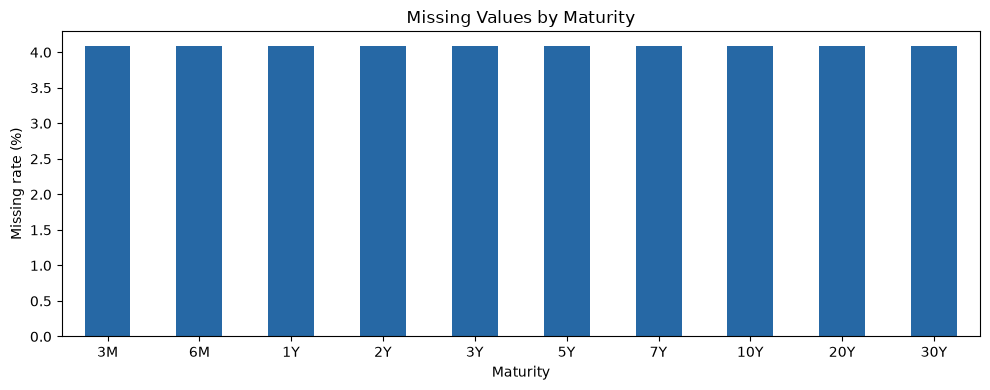

Dates with all maturities missing: 233
Missing rate: 4.09%
Complete observations: 5,466 / 5,699


In [49]:
# Missing values by maturity
missing = pd.DataFrame({
    "Available observations": df.notna().sum(),
    "Missing values": df.isna().sum(),
    "Missing rate (%)": (df.isna().mean() * 100).round(2)
})

display(missing)

# Plot missing values
ax = missing["Missing rate (%)"].plot.bar(figsize=(10, 4), color="#2668A5")
ax.set(title="Missing Values by Maturity", xlabel="Maturity", ylabel="Missing rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Check whether missing dates are shared across maturities
all_missing = df.isna().all(axis=1)

print(f"Dates with all maturities missing: {all_missing.sum()}")
print(f"Missing rate: {missing['Missing rate (%)'].max():.2f}%")
print(f"Complete observations: {df.dropna().shape[0]:,} / {len(df):,}")


The analysis identifies **233 missing dates**, shared across all 10 maturities. These gaps are mainly explained by the US holiday calendar:

- **216 federal holidays**;
- **15 Good Fridays**;
- **2 exceptional market closures**, related to Hurricane Sandy in 2012 and the national day of mourning in 2018.

Since all 10 maturities have missing values on the same dates, these gaps appear to be related to the yield publication calendar rather than issues specific to individual maturities.

For the next steps of the project, these dates can be removed during preprocessing, as no yields are available for any maturity.

## 3. Descriptive Statistics

In [59]:
df.info()
stats = df.describe().T[["count", "mean", "std", "min", "50%", "max"]]
stats.columns = ["Count", "Mean (%)", "Std (%)", "Min (%)", "Median (%)", "Max (%)"]
display(stats.round(2))

<class 'pandas.DataFrame'>
DatetimeIndex: 5699 entries, 2005-01-03 to 2026-11-05
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   3M      5466 non-null   float64
 1   6M      5466 non-null   float64
 2   1Y      5466 non-null   float64
 3   2Y      5466 non-null   float64
 4   3Y      5466 non-null   float64
 5   5Y      5466 non-null   float64
 6   7Y      5466 non-null   float64
 7   10Y     5466 non-null   float64
 8   20Y     5466 non-null   float64
 9   30Y     5466 non-null   float64
dtypes: float64(10)
memory usage: 489.8 KB


,Count,Mean (%),Std (%),Min (%),Median (%),Max (%)
3M,5466.0,1.84,1.97,0.00,0.98,5.63
6M,5466.0,1.93,1.96,0.02,1.14,5.61
1Y,5466.0,1.97,1.87,0.04,1.27,5.49
2Y,5466.0,2.08,1.70,0.09,1.42,5.29
3Y,5466.0,2.21,1.57,0.10,1.60,5.26
5Y,5466.0,2.51,1.36,0.19,2.20,5.23
7Y,5466.0,2.78,1.24,0.36,2.65,5.23
10Y,5466.0,3.03,1.16,0.52,2.90,5.31
20Y,5466.0,3.51,1.13,0.87,3.46,5.71
30Y,5466.0,3.61,1.01,0.99,3.64,5.67


We can see that average yields increase with maturity, from **1.84% for 3M to 3.61% for 30Y**. On the other hand, the standard deviation decreases from **1.97 to 1.01 percentage points**, showing that short-term yield levels have varied more over the period.

These results show some differences between short- and long-term maturities. For our project, it will be interesting to see whether these differences also affect how accurately we can predict yields.

## 4. Historical Evolution

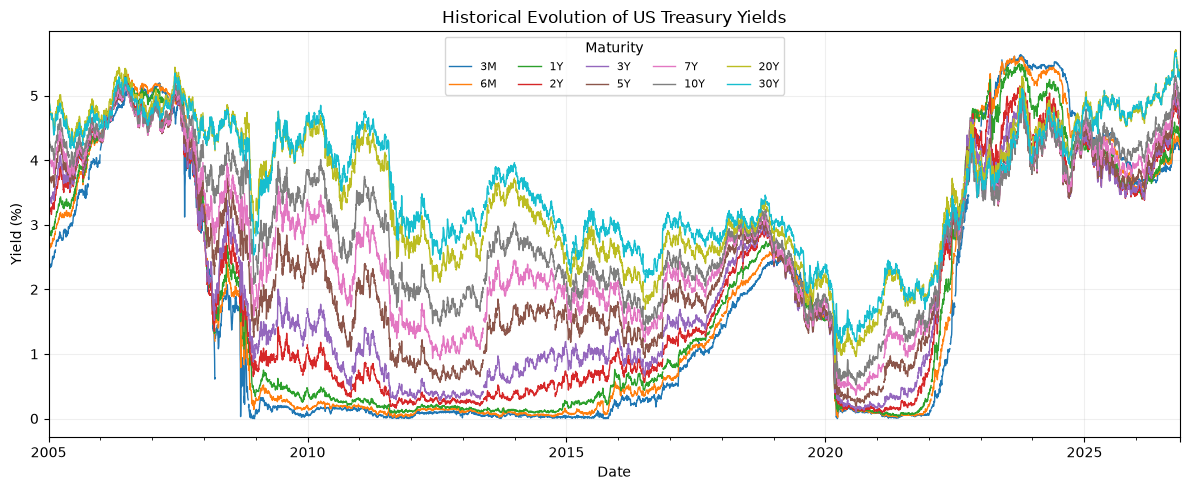

In [50]:
ax = df.plot(figsize=(12, 5), linewidth=1)
ax.set(title="Historical Evolution of US Treasury Yields", xlabel="Date", ylabel="Yield (%)")
ax.grid(alpha=0.2)
ax.legend(title="Maturity", ncol=5, fontsize=8)
plt.tight_layout()
plt.show()

We can see large falls around the 2008 financial crisis and the 2020 pandemic, followed by a strong rise in 2022–2023 as the Fed tightened monetary policy to fight inflation.

The 3M yield reacts strongly to changes in short-term interest rates, while 10Y and 30Y yields also reflect longer-term expectations and term premiums. Sometimes the 3M rate rises above the 10Y or 30Y rate, showing an inverted yield curve.

## 5. Distributions

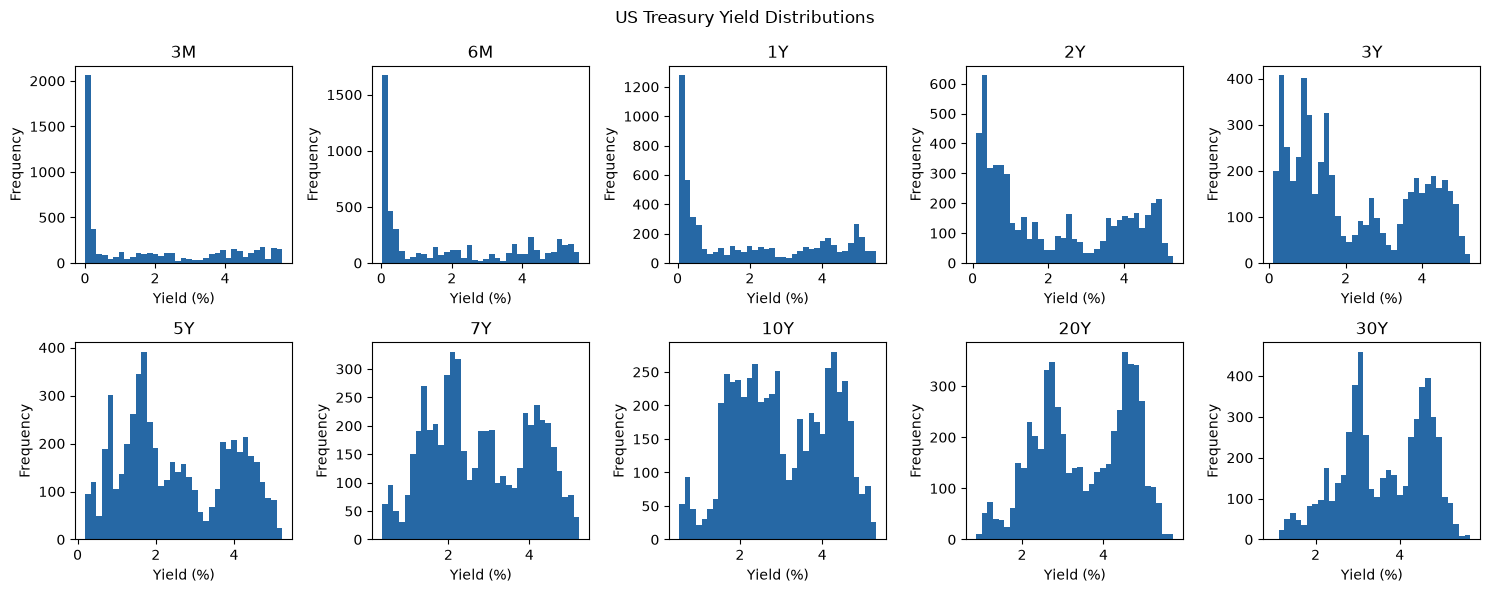

,Skewness
3M,0.61
6M,0.56
1Y,0.50
2Y,0.43
3Y,0.38
5Y,0.25
7Y,0.12
10Y,-0.03
20Y,-0.16
30Y,-0.25


In [53]:
# Yield distributions
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, maturity in zip(axes.flat, df.columns):
    ax.hist(df[maturity].dropna(), bins=35, color="#2668A5")
    ax.set(title=maturity, xlabel="Yield (%)", ylabel="Frequency")

fig.suptitle("US Treasury Yield Distributions")
plt.tight_layout()
plt.show()

# Skewness
display(df.skew().round(2).to_frame("Skewness"))

Short-term yields are heavily concentrated around 0%, mainly due to the accommodative monetary policies implemented after the 2008 and 2020 crises. In contrast, long-term yields show more spread-out distributions with several peaks, reflecting different interest rate regimes over the period studied.

Finally, skewness decreases with maturity, from **+0.61 for 3M to −0.25 for 30Y**. These differences show that yield distributions vary across maturities and do not all follow a normal distribution.

## 6. Correlations


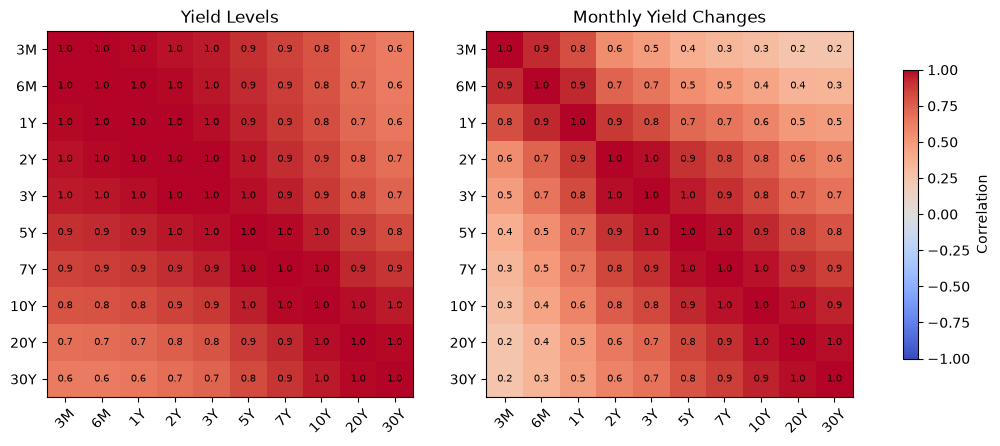

In [56]:
# Monthly yield changes 
monthly = df.dropna().resample("ME").last().dropna()
if monthly.index[-1].to_period("M") == pd.Timestamp.today().to_period("M"):
    monthly = monthly.iloc[:-1]

changes = monthly.diff().dropna() * 100

# Correlation matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, data, title in zip(
    axes,
    [df.corr(), changes.corr()],
    ["Yield Levels", "Monthly Yield Changes"]
):
    im = ax.imshow(data, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set(xticks=range(10), yticks=range(10), title=title)
    ax.set_xticklabels(df.columns, rotation=45)
    ax.set_yticklabels(df.columns)

    for i in range(10):
        for j in range(10):
            ax.text(j, i, f"{data.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)

fig.colorbar(im, ax=axes, shrink=0.75, label="Correlation")
plt.show()

We can see that US Treasury yields are generally highly correlated when looking at their levels, as they follow similar economic trends.

However, when looking at monthly changes, the differences become more noticeable. For example, the correlation between 3M and 30Y drops from **0.6 to 0.2**, while it remains around **0.9 between 3M and 6M**.

This suggests that maturities close to each other tend to move in a similar way, unlike maturities that are further apart. For our project, it will be interesting to see whether these differences affect how predictable interest rates are.

## 7. Extreme Changes (Outliers)

,Extreme Changes (> 3σ)
3M,7
6M,7
1Y,6
2Y,5
3Y,4
5Y,1
7Y,1
10Y,1
20Y,2
30Y,4


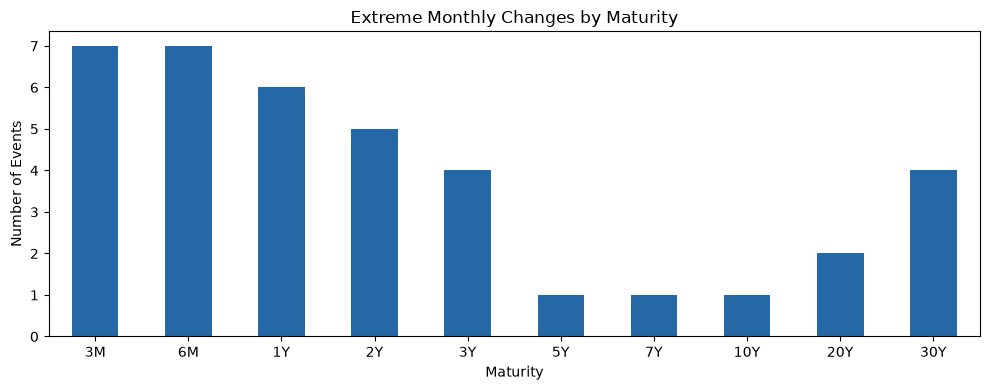

In [58]:

# Detect extreme monthly changes (> 3 standard deviations)
z = (monthly_changes - monthly_changes.mean()) / monthly_changes.std().replace(0, np.nan)  # noqa: F821
outliers = (z.abs() > 3).sum().rename("Extreme Changes (> 3σ)")
display(outliers.to_frame())

# Plot extreme changes by maturity
ax = outliers.plot.bar(figsize=(10, 4), color="#2668A5")
ax.set(title="Extreme Monthly Changes by Maturity",
       xlabel="Maturity", ylabel="Number of Events")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


We can see that short-term maturities have more extreme monthly changes, especially 3M and 6M, with 7 events each, compared to only 1 for 5Y, 7Y, and 10Y.

These movements could be linked to changes in monetary policy or periods of economic uncertainty. For our project, it will be interesting to see whether these extreme changes make some maturities harder to predict.